# Verifying the simulated images

The images from notebook 01 should behave like frames from the real instrument
model. This notebook checks that they do: star centroids land where the WCS
says, aperture photometry closes on the ETC count rates, source-free pixels
follow the analytic noise model, bright stars are flagged as saturated, and the
FITS output round-trips. Every section ends in an assertion, so the notebook
doubles as a smoke test of the pipeline.

**Requirements:** a kernel with `wcc_etc`, `wcc_sim` and `astroquery` installed.
The Gaia query is cached in `gaia_cache/` (shared with notebook 01), so after
the first run it works offline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

import wcc_etc
import wcc_sim
from wcc_sim import simulate_field

from wcc_sim.plotting import use_style, TEAL, RED, AMBER
use_style()

print(f'wcc_sim {wcc_sim.__version__} | wcc_etc {wcc_etc.__version__}')

wcc_sim 0.1.0 | wcc_etc 0.1.0


## 1. The test field

The same pointing, sensor and exposure as notebook 01: the full IMX455 array at
(291.0, 44.5) in `zwo:r`, 90 s, in focus. We also keep a 600 x 600 px subarray
centred on a bright, isolated, unsaturated star at each of the three focus
levels; the astrometric and photometric checks below use it to measure the PSF
without neighbours.

In [2]:
RA0, DEC0 = 291.0, 44.5   # deg, ICRS (Kepler field)
EXPTIME = 90.0             # s

field = simulate_field(
    ra=RA0, dec=DEC0, sensorfilter='zwo:r', focus=0,
    exptime=EXPTIME, seed=42, mag_limit=21.0,
    cache_dir='gaia_cache',
)

p = field.params
print(f"{p['n_sources']} Gaia sources (G <= {p['mag_limit']}), "
      f"{int(field.saturation_mask.sum())} saturated px")
print(f"plate scale {p['plate_scale_mas']:.2f} mas/px | sky {p['sky_e_s']:.3f} + "
      f"dark {p['dark_e_s']:.4f} e-/s/px | read noise {p['read_noise']:.2f} e- | "
      f"gain {p['gain']:.3f} e-/ADU")

img = field.image_adu
cat = field.catalog
inside = np.asarray(cat['in_image'], dtype=bool)
bg = (p['sky_e_s'] + p['dark_e_s']) * EXPTIME      # expected background per pixel [e-]
print(f'{inside.sum()} of {len(cat)} catalog stars land on the array')

100 Gaia sources (G <= 21.0), 167 saturated px
plate scale 16.87 mas/px | sky 0.014 + dark 0.0031 e-/s/px | read noise 3.04 e- | gain 0.261 e-/ADU
50 of 100 catalog stars land on the array


In [3]:
from scipy.spatial import cKDTree

xy = np.c_[cat['x'], cat['y']]
tree = cKDTree(xy)
neigh = tree.query(xy, k=2)[0][:, 1]                  # distance to nearest neighbor [px]
sat = np.asarray(cat['saturated'], dtype=bool)
ok = inside & ~sat & (neigh > 180)                    # isolated: > 3 arcsec
star = cat[ok][np.argmin(cat['phot_g_mean_mag'][ok])]
print(f"star: Gaia DR3 {star['source_id']}  G={star['phot_g_mean_mag']:.2f}  "
      f"spt={star['spt']}  rate={star['rate_e_s']:.0f} e-/s")

fields_focus = {}
for foc in (0, 1, 2):
    fields_focus[foc] = simulate_field(
        ra=float(star['ra']), dec=float(star['dec']), sensorfilter='zwo:r',
        focus=foc, exptime=EXPTIME, seed=42, shape=(600, 600),
        cache_dir='gaia_cache',
    )
print('subarray sims done')

star: Gaia DR3 2126245588779207936  G=18.26  spt=G5V  rate=1912 e-/s


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: divide by zero encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: overflow encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: invalid value encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: divide by zero encountered in matmul
  cy = (psf.sum(axis=1) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: overflow encountered in matmul
  cy = (psf.sum(axis=1) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: invalid value encou

/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: divide by zero encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: overflow encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:35: RuntimeWarning: invalid value encountered in matmul
  cx = (psf.sum(axis=0) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: divide by zero encountered in matmul
  cy = (psf.sum(axis=1) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: overflow encountered in matmul
  cy = (psf.sum(axis=1) @ i) / total
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-sim/src/wcc_sim/psf.py:36: RuntimeWarning: invalid value encou

subarray sims done


## 2. PSF modes: peak ordering

Defocus spreads a star's light over more pixels, so the peak pixel must fall
from in focus to +1 wave to +2 waves. The radial profiles of the noiseless
subarrays show the Airy core and the two rings.

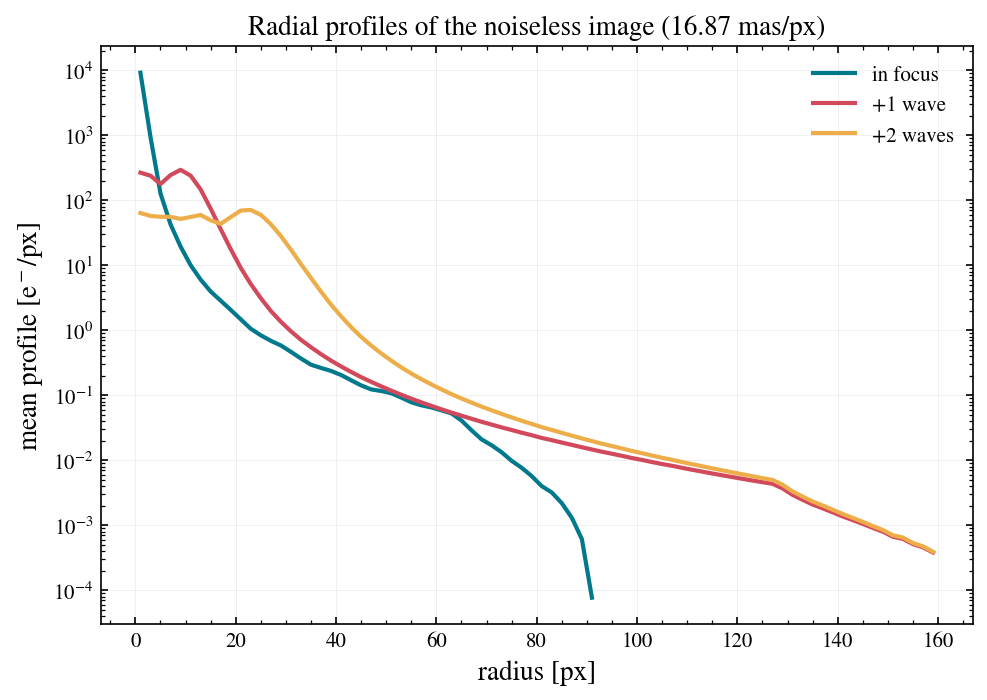

peak pixel: in-focus 14158 e- | +1w 308 e- (2.2%) | +2w 76 e- (0.5%)
PASS: peak ordering in-focus > +1w > +2w


In [4]:
from wcc_sim.plotting import plot_radial_profile

bg = (p['sky_e_s'] + p['dark_e_s']) * EXPTIME
fig, ax = plt.subplots(figsize=(7.5, 5))
for foc, col, lab in [(0, TEAL, 'in focus'), (1, RED, '+1 wave'), (2, AMBER, '+2 waves')]:
    f = fields_focus[foc]
    row = int(np.flatnonzero(f.catalog['source_id'] == star['source_id'])[0])
    plot_radial_profile(f.image_clean, float(f.catalog['x'][row]), float(f.catalog['y'][row]),
                        ax=ax, bg=bg, r_max=160, color=col, label=lab)
ax.set_ylabel('mean profile [e$^-$/px]')
ax.set_title('Radial profiles of the noiseless image (16.87 mas/px)')
plt.show()

peak = {f: fields_focus[f].image_clean.max() - bg for f in (0, 1, 2)}
print(f"peak pixel: in-focus {peak[0]:.0f} e- | +1w {peak[1]:.0f} e- ({peak[1]/peak[0]:.1%}) "
      f"| +2w {peak[2]:.0f} e- ({peak[2]/peak[0]:.1%})")
assert peak[0] > peak[1] > peak[2], 'defocus must lower the peak'
print('PASS: peak ordering in-focus > +1w > +2w')

## 3. Astrometry

Centroid the brightest isolated stars on the noiseless full-frame image and
compare with the catalog positions predicted by the WCS. Sub-pixel placement
uses an 11x oversampled PSF shift, so the quantization floor is 1/22 px, about
0.8 mas; centroids should agree to a few mas.

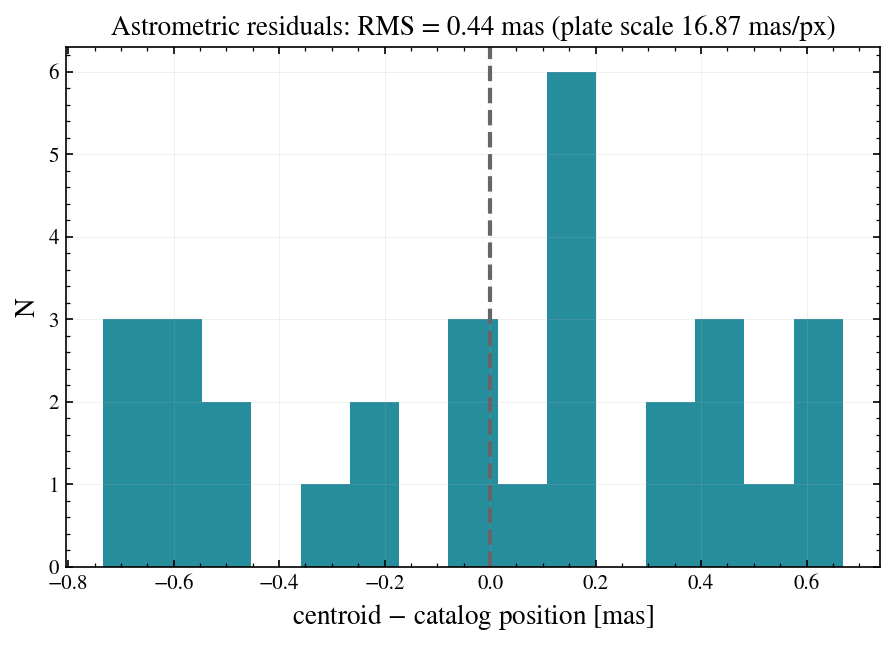

PASS: astrometric RMS 0.44 mas < 10 mas


In [5]:
from photutils.centroids import centroid_com

sel = cat[ok]
sel = sel[np.argsort(sel['phot_g_mean_mag'])][:15]     # 15 brightest isolated stars
clean = field.image_clean
h = 20
resid_mas = []
for s in sel:
    x0, y0 = int(round(s['x'])), int(round(s['y']))
    if not (h < x0 < clean.shape[1] - h and h < y0 < clean.shape[0] - h):
        continue
    cut = clean[y0 - h:y0 + h + 1, x0 - h:x0 + h + 1] - bg
    cx, cy = centroid_com(np.clip(cut, 0, None))
    resid_mas.append(((x0 - h + cx) - s['x']) * 16.87), resid_mas.append(((y0 - h + cy) - s['y']) * 16.87)

resid_mas = np.array(resid_mas)
rms = np.sqrt(np.mean(resid_mas ** 2))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(resid_mas, bins=15, color=TEAL, alpha=0.85)
ax.axvline(0, color='0.4', ls='--')
ax.set_xlabel('centroid $-$ catalog position [mas]'); ax.set_ylabel('N')
ax.set_title(f'Astrometric residuals: RMS = {rms:.2f} mas (plate scale 16.87 mas/px)')
plt.show()

assert rms < 10, f'astrometric RMS too large: {rms:.2f} mas'
print(f'PASS: astrometric RMS {rms:.2f} mas < 10 mas')

## 4. Photometric closure

Aperture photometry (r = 40 px, annulus background) on both the noiseless and
the noisy image, compared with each star's expected flux `rate_e_s x exptime`
from the ETC chain times the fraction of the PSF the aperture captures. That
fraction is measured the same way on the noiseless in-focus subarray of section
1: the diffraction wings and the scattered-light halo put a few percent of every
star's light beyond 40 px, so a raw aperture sum does not close on the total
rate. With the aperture fraction taken out, the noiseless measurements should
close to about 1% and the noisy scatter should stay inside the propagated noise
envelope.

aperture fraction at r = 40 px: 0.9796


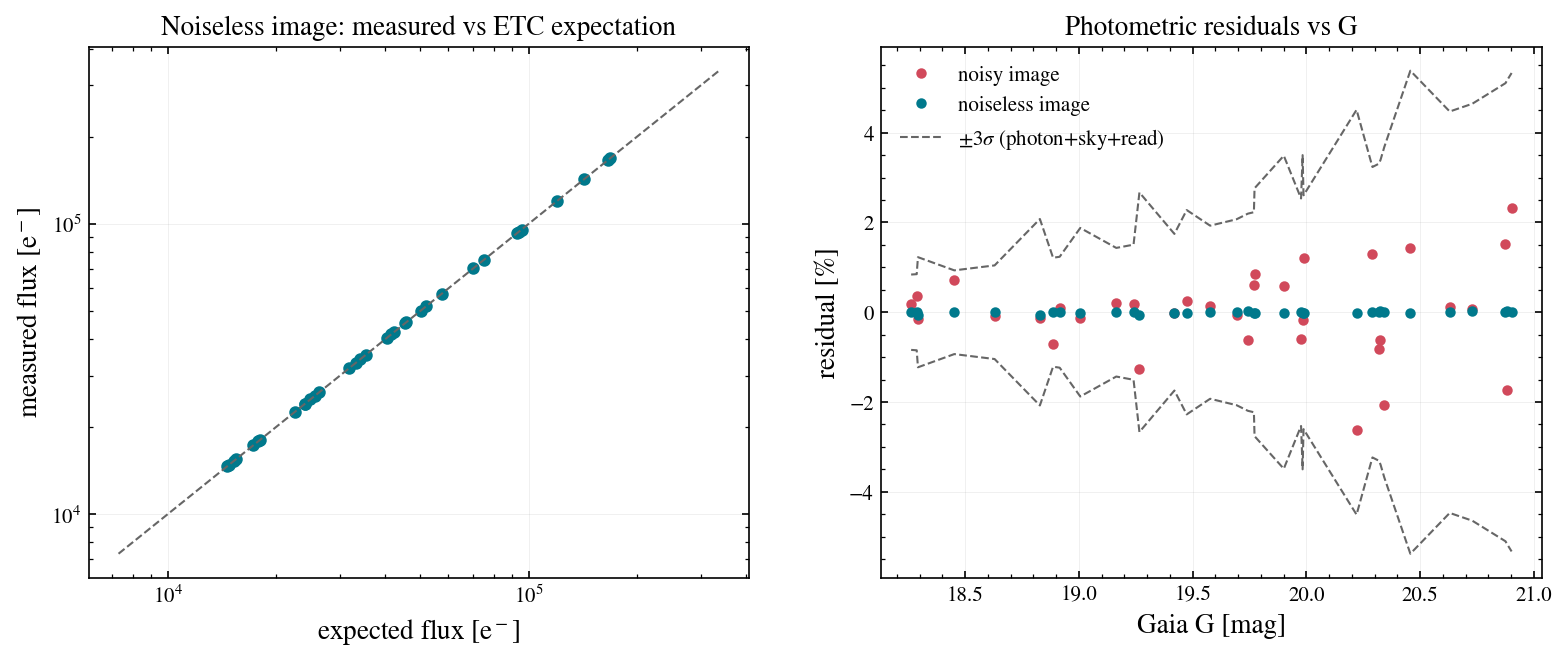

noiseless closure: median |resid| = 0.01%  (n=34)
noisy photometry: 100% of stars within 3 sigma of expectation
PASS: photometry closes on the ETC prediction


In [6]:
from photutils.aperture import CircularAnnulus, CircularAperture, aperture_photometry

R_AP, R_IN, R_OUT = 40, 60, 90
m = ok & (cat['x'] > R_OUT) & (cat['x'] < img.shape[1] - R_OUT) \
       & (cat['y'] > R_OUT) & (cat['y'] < img.shape[0] - R_OUT)
stars = cat[m]
pos = np.c_[stars['x'], stars['y']]
aper, ann = CircularAperture(pos, r=R_AP), CircularAnnulus(pos, r_in=R_IN, r_out=R_OUT)

def measure(image):
    phot = aperture_photometry(image, aper)
    bkg = aperture_photometry(image, ann)['aperture_sum'] / ann.area
    return np.asarray(phot['aperture_sum'] - bkg * aper.area)

# aperture fraction of the model PSF: same aperture + annulus on the isolated star of section 1
sub = fields_focus[0]
xs, ys = float(sub.catalog['x'][sub.catalog['source_id'] == star['source_id']][0]), \
         float(sub.catalog['y'][sub.catalog['source_id'] == star['source_id']][0])
ap1, ann1 = CircularAperture((xs, ys), r=R_AP), CircularAnnulus((xs, ys), r_in=R_IN, r_out=R_OUT)
flux1 = (aperture_photometry(sub.image_clean, ap1)['aperture_sum'][0]
         - aperture_photometry(sub.image_clean, ann1)['aperture_sum'][0] / ann1.area * ap1.area)
ee_ap = float(flux1 / (star['rate_e_s'] * EXPTIME))
print(f'aperture fraction at r = {R_AP} px: {ee_ap:.4f}')

expected = np.asarray(stars['rate_e_s']) * EXPTIME * ee_ap
meas_clean = measure(field.image_clean)
meas_noisy = measure(field.image_e)

resid_clean = 100 * (meas_clean - expected) / expected
resid_noisy = 100 * (meas_noisy - expected) / expected
npix = np.pi * R_AP ** 2
sigma_pct = 100 * np.sqrt(expected + npix * bg + npix * p['read_noise'] ** 2) / expected

g = np.asarray(stars['phot_g_mean_mag'])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].loglog(expected, meas_clean, 'o', color=TEAL, ms=5)
lims = [expected.min() * 0.5, expected.max() * 2]
axes[0].plot(lims, lims, color='0.4', ls='--', lw=1)
axes[0].set_xlabel('expected flux [e$^-$]'); axes[0].set_ylabel('measured flux [e$^-$]')
axes[0].set_title('Noiseless image: measured vs ETC expectation')

order = np.argsort(g)
axes[1].plot(g, resid_noisy, 'o', color=RED, ms=4, label='noisy image')
axes[1].plot(g, resid_clean, 'o', color=TEAL, ms=4, label='noiseless image')
axes[1].plot(g[order], 3 * sigma_pct[order], color='0.4', ls='--', lw=1, label=r'$\pm3\sigma$ (photon+sky+read)')
axes[1].plot(g[order], -3 * sigma_pct[order], color='0.4', ls='--', lw=1)
axes[1].set_xlabel('Gaia G [mag]'); axes[1].set_ylabel('residual [%]')
axes[1].set_title('Photometric residuals vs G')
axes[1].legend()
plt.show()

med = np.median(np.abs(resid_clean))
frac_in = np.mean(np.abs(resid_noisy) < 3 * sigma_pct)
print(f'noiseless closure: median |resid| = {med:.2f}%  (n={len(stars)})')
print(f'noisy photometry: {100*frac_in:.0f}% of stars within 3 sigma of expectation')
assert med < 2.0, 'noiseless closure worse than 2%'
assert frac_in > 0.9, 'too many noisy measurements outside 3 sigma'
print('PASS: photometry closes on the ETC prediction')

## 5. Noise statistics

A source-free simulation should be pure sky, dark and read noise: pixel
variance equal to (sky + dark) t + RN^2, with a near-Gaussian histogram at
these count levels.

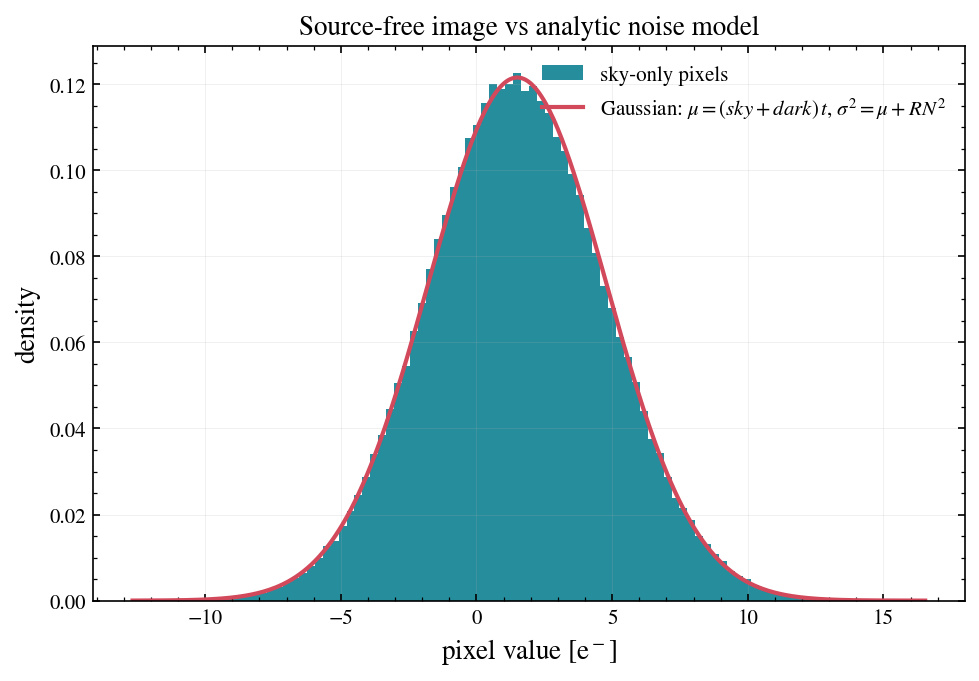

mean: measured 1.50 vs expected 1.50 e-
var : measured 10.79 vs expected 10.77 e-^2
PASS: noise statistics match (sky+dark)*t + RN^2


In [7]:
from astropy.table import Table
from wcc_sim.catalog import _empty_table

sky_field = simulate_field(ra=RA0, dec=DEC0, sensorfilter='zwo:r', focus=0,
                           exptime=EXPTIME, seed=7, shape=(512, 512),
                           catalog=_empty_table())
pix = sky_field.image_e.ravel()
lam = (p['sky_e_s'] + p['dark_e_s']) * EXPTIME
var_exp = lam + p['read_noise'] ** 2

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.hist(pix, bins=100, density=True, color=TEAL, alpha=0.85, label='sky-only pixels')
xx = np.linspace(pix.min(), pix.max(), 400)
ax.plot(xx, np.exp(-(xx - lam) ** 2 / (2 * var_exp)) / np.sqrt(2 * np.pi * var_exp),
        color=RED, label=r'Gaussian: $\mu=(sky+dark)\,t$, $\sigma^2=\mu+RN^2$')
ax.set_xlabel('pixel value [e$^-$]'); ax.set_ylabel('density')
ax.set_title('Source-free image vs analytic noise model')
ax.legend()
plt.show()

print(f'mean: measured {pix.mean():.2f} vs expected {lam:.2f} e-')
print(f'var : measured {pix.var():.2f} vs expected {var_exp:.2f} e-^2')
assert abs(pix.mean() - lam) < 0.05 * max(lam, 1), 'mean off'
assert abs(pix.var() - var_exp) < 0.10 * var_exp, 'variance off'
print('PASS: noise statistics match (sky+dark)*t + RN^2')

## 6. Saturation flags

Bright stars overfill the detector wells. The pipeline flags the affected
pixels in the `SATMASK` extension and each affected star in the catalog.
`plot_image()` works on any array; here it shows a cutout of the ADU image
around the brightest saturated star with the matching slice of the mask drawn
as a contour.

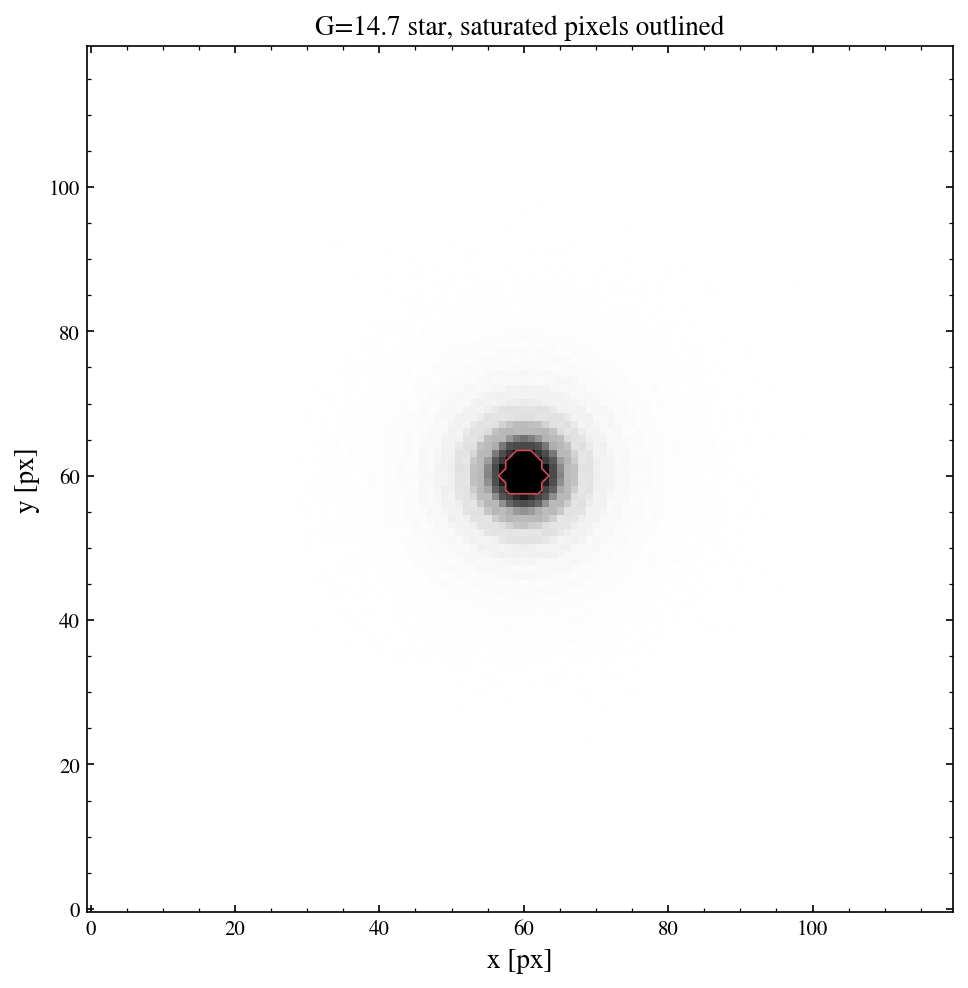

14 saturated stars in frame; brightest G=14.71


In [8]:
from wcc_sim.plotting import plot_image

sat_stars = cat[np.asarray(cat['saturated'], dtype=bool) & inside]
if len(sat_stars):
    s = sat_stars[np.argmin(sat_stars['phot_g_mean_mag'])]
    x0, y0 = int(round(s['x'])), int(round(s['y']))
    h = 60
    sl = np.s_[max(y0-h,0):y0+h, max(x0-h,0):x0+h]
    ax = plot_image(field.image_adu[sl], satmask=field.saturation_mask[sl], percent=99.9)
    ax.set_title(f"G={s['phot_g_mean_mag']:.1f} star, saturated pixels outlined")
    plt.show()
    print(f"{len(sat_stars)} saturated stars in frame; brightest G={s['phot_g_mean_mag']:.2f}")
else:
    print('no saturated stars in this field/exptime')

## 7. FITS round trip

The multi-extension file written by `field.write()` must come back with its
four extensions, and the catalog table must hold as many rows as the `NSRC`
header card says.

In [9]:
import os, tempfile

path = os.path.join(tempfile.mkdtemp(), 'field_1wave.fits')
fields_focus[1].write(path)
with fits.open(path) as f_check:
    names = [h.name for h in f_check]
    n_cat = len(f_check['CAT'].data)
    hdr = f_check['SCI'].header
print('extensions:', names)
print(f"CAT rows {n_cat} | NSRC card {hdr['NSRC']} | WCS {hdr['CTYPE1']}, {hdr['CTYPE2']}")
assert names == ['SCI', 'SATMASK', 'CAT', 'CLEAN']
assert n_cat == hdr['NSRC']
print('PASS: FITS output round-trips (SCI/SATMASK/CAT/CLEAN)')

extensions: ['SCI', 'SATMASK', 'CAT', 'CLEAN']
CAT rows 7 | NSRC card 7 | WCS RA---TAN, DEC--TAN
PASS: FITS output round-trips (SCI/SATMASK/CAT/CLEAN)


## Summary

Verified in this notebook:

1. PSF modes: the in-focus Airy and the +1/+2-wave Huygens defocus PSFs render
   with the expected peak ordering and ring structure.
2. Astrometry: star centroids match the Gaia/WCS positions to a few-mas RMS.
3. Photometry: aperture fluxes close on the ETC `rate x t` prediction to about
   1% (noiseless) and scatter within the propagated noise envelope (noisy).
4. Noise: source-free pixels follow mean = (sky + dark) t and variance =
   mean + RN^2.
5. Saturation and FITS: bright stars are flagged in `SATMASK` and `CAT`, and
   the multi-extension FITS output round-trips.

The ETC-versus-simulation cross-check also runs as a slow test in the test
suite (`pytest -m slow`). The plots came from `field.plot_cutout()`,
`plot_radial_profile()` and `plot_image()`; notebook 10 shows the rest of the
plotting methods.